# Agente de óptica: simula con `pyavzutilsV2` y aprende a detectar errores comunes

Este agente es una versión especializada del agente investigador del reto 2. Recibe una petición de óptica, por ejemplo *"simula la difracción de una abertura circular de 1 mm a 20 cm con λ = 633 nm"* o *"revisa este código de propagación"*, y hace cuatro cosas:

1. **Diagnostica antes de simular.** Revisa unidades, muestreo, *aliasing*, precisión numérica y si la aproximación es válida, todo con fórmulas y no "a ojo".
2. **Simula con tu librería.** Llama a `pyavzutilsV2` (`ASMprop`/`ASM`, `propft`/`convprop`, `ASMtf`) solo cuando hace falta, siempre a través de envoltorios que evitan los fallos conocidos de la librería.
3. **Se revisa.** Un revisor automático rechaza la respuesta si el diagnóstico encontró un error y la respuesta no lo menciona. Es el patrón de reflexión.
4. **Aprende.** Tiene una **base de errores** (`errores_optica.json`) que crece con el uso. Cada error tiene síntomas, causa, solución y, si se puede, un patrón para detectarlo automáticamente en código. Después de cada sesión, el agente propone lecciones nuevas, cuenta cuántas veces aparece cada error y tiene en cuenta tu retroalimentación (útil / no útil). Las lecciones más relevantes se inyectan en el *prompt* de la siguiente sesión.

| Patrón (lab 1) | Dónde aparece |
|---|---|
| Herramientas | Diagnóstico, simulación, pruebas de validación, revisión de código y consulta de la base |
| Reflexión | Revisor automático + revisor LLM |
| Memoria / aprendizaje | Base de errores persistente con recuperación por relevancia |

## Requisitos

```bash
pip install ollama torch torchvision opencv-python numpy matplotlib
ollama pull qwen3:1.7b      # o llama3.2:3b / llama3.1:8b
```

`pyavzutilsV2.py` debe estar en la misma carpeta que este notebook.

In [16]:
import json, re, math, time, textwrap, unicodedata, copy
from pathlib import Path
from types import SimpleNamespace as NS
from contextlib import contextmanager
import numpy as np
import torch
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=UserWarning)

import pyavzutilsV2 as pz          # libreria base
MODELO = "qwen2.5:3b"
CARPETA = Path("salidas_agente_optica"); CARPETA.mkdir(exist_ok=True)
RUTA_BASE = Path("errores_optica.json")
CONTAR_DETECCIONES = False     # se activa en la sección 6; así las demostraciones no alteran tu base

## 1. La librería `pyavzutilsV2`

`pyavzutilsV2` es una librería de PyTorch que el **Grupo de Óptica y Fotónica** usa de forma recurrente para simular y procesar campos ópticos. Reúne en un solo archivo las operaciones que más se repiten en el trabajo del grupo: propagar un campo, hacer la transformada de Fourier con una lente, recortar e insertar regiones de una imagen y diseñar hologramas. Como está escrita en PyTorch, los mismos cálculos corren en CPU o en GPU y se pueden integrar en modelos que se entrenan con gradientes.

### Qué contiene

| Grupo | Funciones | Para qué sirven |
|---|---|---|
| Propagación por espectro angular (ASM) | `ASMprop`, `ASM`, `ASMpropnp`, `ASMnp` | Propagación escalar exacta a una distancia `z`. `ASMprop` construye la función de transferencia $e^{i2\pi z\sqrt{1/\lambda^2-f_x^2-f_y^2}}$ con el relleno (*padding*) necesario, y `ASM` la aplica al campo. Las versiones `np` no usan *padding*. |
| Propagación de Fresnel | `propft`, `cil`, `convprop` | Función de transferencia paraxial $e^{-i\pi\lambda z(f_x^2+f_y^2)}$. `cil` es la versión cilíndrica (un solo eje) y `convprop` la aplica por convolución en el dominio de Fourier. |
| Lentes | `ASMtf`, `ASMitf` | Transformada de Fourier óptica (y su inversa) con una lente de focal `f`: propagar `f`, aplicar la fase de la lente y propagar `f` otra vez. |
| Transformadas de Fourier centradas | `tfourier`, `itfourier`, `tfouriern`, `itfouriern` | FFT 2D con el origen en el centro de la imagen. |
| Recorte e inserción | `tajada`, `fusion` (coordenadas centradas), `tajadan`, `fusionn` (índices de matriz) | Extraer o pegar una región de un arreglo, por ejemplo para trabajar con el área activa de un SLM dentro de una ventana más grande. |
| Diseño de hologramas | `Ofrapgen`, `Ifrta` | Algoritmos iterativos tipo Gerchberg–Saxton que buscan la fase que produce una intensidad objetivo. |
| Utilidades | `corr2`, `comb2d`, `Imshow`, `Videoshow`, `abwavephase` | Correlación entre imágenes, peine 2D, mostrar imágenes o video en pantalla completa (por ejemplo en un SLM) y fase de aberraciones (Zernike). |

Las funciones de propagación reciben un objeto `args` con los parámetros físicos: `wl` (longitud de onda), `dx`, `dy` (tamaño de píxel), `sx`, `sy` (píxeles), `z` (distancia) y, para las lentes, `f` y `device`. **Todas las longitudes deben estar en las mismas unidades.**

### Precauciones al usarla

Como cualquier código de investigación, la librería tiene detalles que conviene conocer. Estos son los que aparecen al compararla con casos de solución analítica: un haz gaussiano, cuyo ancho es $w(z)=w_0\sqrt{1+(z/z_R)^2}$, y el patrón de Airy, cuyo primer cero está en $r_1 = 1.22\,\lambda f/D$. Se reproducen en la sección 3 y forman parte de la base de errores inicial del agente.

| # | Función | Detalle | Consecuencia |
|---|---|---|---|
| L1 | `ASMprop` + `ASM` | Calcula la fase en **float32**. Esa fase es del orden de $2\pi z/\lambda \sim 10^6$ rad, y float32 solo tiene unos 7 dígitos. | Ruido de fase: el haz gaussiano sale 2–3 % más ancho a z ≥ 10 cm. En float64 el error es 0. |
| L2 | `ASMprop` | Con `N` impar, el vector de frecuencias se construye con un límite equivocado. | Resultado incorrecto **sin mensaje de error**. |
| L3 | `ASMprop` | El *padding* intercambia x e y (`ConstantPad2d` espera *(izq, der, arriba, abajo)*). | Solo afecta píxeles rectangulares (`dx ≠ dy`). |
| L4 | `ASMprop` | `asin(λ/(2dx))` da NaN si `dx < λ/2`. | No sirve para muestreo sub-longitud de onda. |
| L5 | `ASMtf`/`ASMitf` | Necesitan `args.sx`/`args.sy`, **sobrescriben `args.z = f`** y usan `dx` también en y. | La siguiente propagación ocurre a la distancia focal. |
| L6 | `propft` + `convprop` | Fresnel por función de transferencia solo está bien muestreado si $z \le z_c = N\,dx^2/\lambda$. | *Aliasing* para $z > z_c$. |
| L7 | `convprop`, `tfourier` | `fftshift` e `ifftshift` solo son equivalentes con `N` par. | Con `N` impar, el campo queda desplazado un píxel. |
| L8 | `Videoshow` | Usa un nombre de archivo fijo en vez del argumento `file` y sale del ciclo tras el primer cuadro. | Muestra un solo cuadro de otro archivo. |
| L9 | `abwavephase` | Está incompleta. | `UnboundLocalError` al llamarla. |
| L10 | `tajadan`/`fusionn` | El docstring dice "centrada", pero el código usa la esquina superior izquierda. | Recortes desplazados si se confunden con `tajada`/`fusion`. |

El agente **no modifica la librería**. La usa a través de envoltorios (sección 3) que trabajan en float64, rechazan `N` impar en ASM, copian `args` y verifican el muestreo antes de simular.

## 2. Base de errores (la "memoria" del agente)

Cada entrada tiene:
- `id`, `titulo`, `sintomas`, `causa`, `solucion`, `palabras_clave`.
- `patron` *(opcional)*: una expresión regular que detecta el error directamente en el código.
- `origen`: `semilla` (escrita aquí) o `aprendido` (propuesta por el agente y validada).
- `veces_detectado` y `confianza`: se actualizan solos. La confianza sube cuando marcas una detección como útil y baja cuando no.

La consulta ordena por relevancia, que es la coincidencia de palabras ponderada por la confianza y la frecuencia. Así, los errores que más te pasan aparecen primero.

In [17]:
def _normalizar(t):
    t = unicodedata.normalize("NFD", t.lower())
    return "".join(c for c in t if unicodedata.category(c) != "Mn")

def _tokens(t):
    return set(w for w in re.findall(r"[a-z0-9_]+", _normalizar(t)) if len(w) > 2)

ERRORES_SEMILLA = [
 dict(id="E01", titulo="Unidades mezcladas (mm, µm y m)",
      sintomas="λ o dx con valores absurdos (p. ej. wl=633e-6 creyendo que son metros); patrones de difracción diminutos o gigantes.",
      causa="Mezclar milímetros y metros en λ, dx, z o f. La librería espera todo en las MISMAS unidades.",
      solucion="Trabajar todo en metros: λ ~ 1e-7–2e-5 m, dx ~ 1e-7–1e-3 m. Definir constantes um=1e-6, mm=1e-3.",
      palabras_clave="unidades metros milimetros micras longitud onda wl dx escala", patron=None),
 dict(id="E02", titulo="Muestreo sub-longitud de onda en ASM (dx < λ/2)",
      sintomas="NaN en ASMprop o error 'narrow(): length must be non-negative'.",
      causa="ASMprop calcula asin(λ/(2dx)); si dx<λ/2 el argumento es >1. Además aparecen ondas evanescentes (sqrt de número negativo).",
      solucion="Usar dx ≥ λ/2 o reescribir el propagador con sqrt compleja y sin el margen por asin.",
      palabras_clave="evanescente nan asin muestreo subonda dx asm", patron=None),
 dict(id="E03", titulo="Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ)",
      sintomas="Energía que reaparece por los bordes, réplicas del patrón, anillos falsos a distancias grandes.",
      causa="La fase cuadrática exp(-iπλz f²) de propft varía más rápido de lo que la malla de frecuencias puede muestrear cuando z > z_c = N dx²/λ.",
      solucion="Para z > z_c usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z.",
      palabras_clave="fresnel aliasing propft transferencia muestreo distancia critica bordes replicas", patron=r"\bpropft\s*\("),
 dict(id="E04", titulo="Precisión float32 en ASM",
      sintomas="Haz gaussiano más ancho que la teoría, energía no conservada, ruido de fase que crece con z.",
      causa="La fase 2π z sqrt(1/λ²-f²) es ~1e6 rad; en float32 (7 dígitos) el error absoluto de fase es ~0.1 rad.",
      solucion="Calcular ASMprop en float64 (torch.set_default_dtype(torch.float64)) y usar campos complex128, o restar la portadora 1/λ.",
      palabras_clave="float32 complex64 precision fase ancho energia asm doble", patron=r"(complex64|float32)"),
 dict(id="E05", titulo="Padding enorme en ASMprop",
      sintomas="Mensaje 'Precaucion ... padding de mas de N píxeles', memoria agotada, cálculo lento.",
      causa="El margen es z·tan(asin(λ/2dx))/dx píxeles por lado: crece lineal con z.",
      solucion="Aceptar un ángulo máximo menor (filtro de banda limitada de Matsushima), aumentar dx o propagar por pasos.",
      palabras_clave="padding memoria margen lento asm", patron=None),
 dict(id="E06", titulo="N impar en ASMprop (malla de frecuencias incorrecta)",
      sintomas="El resultado no coincide con la teoría pero no hay error; Prop.shape no es N+2·margen.",
      causa="Para N impar ASMprop usa arange(-(Tfx/2-dfx)/2, ...): el límite inferior está mal y la malla queda de ~3/4 del tamaño.",
      solucion="Usar N par (rellenar con una fila/columna de ceros).",
      palabras_clave="impar tamano frecuencias asm malla", patron=None),
 dict(id="E07", titulo="Píxeles rectangulares (dx ≠ dy) en ASMprop / ASMtf",
      sintomas="Patrón estirado en un eje, padding aplicado al eje equivocado.",
      causa="ConstantPad2d recibe (margy,margy,margx,margx) pero PyTorch espera (izq,der,arriba,abajo); ASMtf usa dx en y.",
      solucion="Usar dx = dy, o intercambiar el orden del padding en una copia corregida de la función.",
      palabras_clave="dx dy rectangular pixel padding eje", patron=None),
 dict(id="E08", titulo="Fuera del régimen paraxial (aproximación de Fresnel)",
      sintomas="Diferencias entre Fresnel y ASM a distancias cortas o con ángulos grandes.",
      causa="Fresnel exige z³ ≫ π/(4λ)·máx[(x-ξ)²+(y-η)²]² (condición suficiente, conservadora).",
      solucion="Usar ASM (exacta para ondas escalares) a distancias cortas.",
      palabras_clave="paraxial fresnel aproximacion distancia corta angulo", patron=None),
 dict(id="E09", titulo="Energía no conservada",
      sintomas="Σ|u|² cambia entre el plano de entrada y el de salida en una propagación sin pérdidas.",
      causa="Aliasing, recorte por la ventana, precisión numérica o normalización incorrecta de la FFT.",
      solucion="Comprobar siempre Σ|u_out|²/Σ|u_in|² ≈ 1; si no, revisar E03, E04, E12.",
      palabras_clave="energia conservacion parseval norma potencia", patron=None),
 dict(id="E10", titulo="Confundir amplitud con intensidad",
      sintomas="Perfiles con la forma correcta pero anchos o contrastes que no coinciden con la teoría.",
      causa="Graficar o comparar |u| cuando la teoría (Airy, sinc², w(z)) se refiere a I = |u|².",
      solucion="Usar I = |u|**2 para comparar con fórmulas de intensidad.",
      palabras_clave="intensidad amplitud abs cuadrado perfil", patron=r"\b[Ii](nt\w*)?\s*=\s*(torch\.|np\.)?abs\([^)]*\)\s*(#.*)?$"),
 dict(id="E11", titulo="ASMtf/ASMitf modifican args.z",
      sintomas="Después de una transformada con lente, la siguiente propagación ocurre a la distancia focal.",
      causa="ASMtf ejecuta args.z = f sobre el objeto que le pasas; además exige args.sx y args.sy.",
      solucion="Pasar una copia: pz.ASMtf(A, copy.copy(args)), con sx, sy iguales a A.shape.",
      palabras_clave="asmtf asmitf lente transformada args mutado focal", patron=r"\bASMi?tf\s*\("),
 dict(id="E12", titulo="El objeto ocupa demasiado de la ventana (wrap-around)",
      sintomas="El patrón difractado choca con los bordes y reaparece por el lado opuesto.",
      causa="La FFT impone periodicidad: si el campo crece hasta el borde, se mezcla con sus réplicas.",
      solucion="Que el objeto ocupe ≲ 1/2 de la ventana y vigilar la fracción de energía en los bordes.",
      palabras_clave="ventana bordes periodicidad wrap objeto tamano relleno", patron=None),
 dict(id="E13", titulo="Videoshow / abwavephase defectuosas",
      sintomas="Videoshow muestra un solo cuadro de otro archivo; abwavephase lanza UnboundLocalError.",
      causa="Videoshow tiene el nombre del archivo fijo y un 'else: break'; abwavephase está incompleta.",
      solucion="No usarlas; para video usar cv2.VideoCapture(file) en un ciclo propio; para Zernike usar una implementación completa.",
      palabras_clave="videoshow video abwavephase zernike aberraciones", patron=r"\b(Videoshow|abwavephase)\s*\("),
 dict(id="E14", titulo="Confundir tajada/fusion (centradas) con tajadan/fusionn (esquina)",
      sintomas="Recortes o inserciones desplazados medio tamaño.",
      causa="tajadan/fusionn usan la esquina superior izquierda aunque su docstring diga 'centrada'.",
      solucion="Usar tajada/fusion para coordenadas centradas y tajadan/fusionn para índices de matriz.",
      palabras_clave="tajada fusion recorte insertar coordenadas centrado esquina", patron=r"\b(tajadan|fusionn)\s*\("),
 dict(id="E15", titulo="fftshift/ifftshift con N impar",
      sintomas="Campo desplazado un píxel, fase lineal espuria.",
      causa="convprop aplica fftshift antes de la FFT; para N impar debería ser ifftshift.",
      solucion="Usar N par o ifftshift antes de fft2 y fftshift después de ifft2.",
      palabras_clave="fftshift ifftshift impar desplazamiento centro fft", patron=None),
]

class BaseErrores:
    def __init__(self, ruta=RUTA_BASE):
        self.ruta = Path(ruta)
        if self.ruta.exists():
            self.errores = json.loads(self.ruta.read_text(encoding="utf-8"))
        else:
            self.errores = [dict(e, origen="semilla", veces_detectado=0, confianza=1.0) for e in ERRORES_SEMILLA]
            self.guardar()

    def guardar(self):
        self.ruta.write_text(json.dumps(self.errores, ensure_ascii=False, indent=1), encoding="utf-8")

    def get(self, id_):
        return next((e for e in self.errores if e["id"] == id_), None)

    def marcar_detectado(self, id_):
        if not CONTAR_DETECCIONES: return          # las celdas de demostración no cuentan
        e = self.get(id_)
        if e: e["veces_detectado"] += 1; self.guardar()

    def retroalimentar(self, id_, util: bool):
        """Tu opinión sobre una detección: sube o baja su confianza (entre 0.2 y 3)."""
        e = self.get(id_)
        if e:
            e["confianza"] = float(np.clip(e["confianza"] * (1.25 if util else 0.7), 0.2, 3.0)); self.guardar()

    def consultar(self, texto, k=5):
        q = _tokens(texto)
        puntajes = []
        for e in self.errores:
            doc = _tokens(" ".join([e["titulo"], e["sintomas"], e["causa"], e["palabras_clave"]]))
            s = len(q & doc) * e["confianza"] * (1 + 0.1 * math.log1p(e["veces_detectado"]))
            if s > 0: puntajes.append((s, e))
        puntajes.sort(key=lambda t: -t[0])
        return [e for _, e in puntajes[:k]]

    def registrar(self, titulo, sintomas, causa, solucion, palabras_clave, patron=None):
        """Agrega una lección aprendida, si es válida y no está repetida. Devuelve (ok, mensaje)."""
        if not all(str(x).strip() for x in (titulo, sintomas, causa, solucion)):
            return False, "Faltan campos (título, síntomas, causa y solución son obligatorios)."
        if patron:
            try: re.compile(patron)
            except re.error as exc: return False, f"Patrón regex inválido: {exc}"
        nuevo = _tokens(titulo + " " + palabras_clave)
        for e in self.errores:
            viejo = _tokens(e["titulo"] + " " + e["palabras_clave"])
            if len(nuevo & viejo) / max(1, len(nuevo | viejo)) > 0.5:
                return False, f"Ya existe una lección parecida: {e['id']} ({e['titulo']})."
        nid = f"A{sum(e['origen'] == 'aprendido' for e in self.errores) + 1:02d}"
        self.errores.append(dict(id=nid, titulo=titulo, sintomas=sintomas, causa=causa, solucion=solucion,
                                 palabras_clave=palabras_clave, patron=patron or None,
                                 origen="aprendido", veces_detectado=0, confianza=1.0))
        self.guardar()
        return True, nid

BASE = BaseErrores()
print(len(BASE.errores), "errores en la base;", sum(e["origen"] == "aprendido" for e in BASE.errores), "aprendidos")

15 errores en la base; 0 aprendidos


## 3. Capa física: envoltorios seguros de la librería y diagnóstico

- `diagnosticar(...)` revisa los parámetros **antes** de simular y devuelve hallazgos con el `id` de la base de errores.
- `propagar(...)` llama a `pz.ASMprop`/`pz.ASM` o a `pz.propft`/`pz.convprop` en float64, sin tocar la librería.
- `lente_tf(...)` llama a `pz.ASMtf` sobre una copia de `args`.
- `metricas(...)` mide la energía relativa, la fracción de energía en los bordes y el ancho RMS: son los síntomas de E03, E09 y E12.

In [18]:
SESION = {"hallazgos": []}      # lo que se detectó en la sesión actual (lo usa el revisor)

@contextmanager
def precision64():
    viejo = torch.get_default_dtype(); torch.set_default_dtype(torch.float64)
    try: yield
    finally: torch.set_default_dtype(viejo)

def _hallazgo(lista, id_, detalle, severidad="error"):
    e = BASE.get(id_)
    lista.append({"id": id_, "titulo": e["titulo"] if e else id_, "severidad": severidad, "detalle": detalle,
                  "solucion": e["solucion"] if e else ""})
    BASE.marcar_detectado(id_)

def diagnosticar(wl, dx, N, z, metodo="asm", dy=None, tamano=None, dtype="float64"):
    h = []
    if not (1e-7 <= wl <= 2e-5):
        _hallazgo(h, "E01", f"λ = {wl:g}: fuera del rango óptico en metros (1e-7 a 2e-5). ¿Está en mm o µm?")
    if not (1e-7 <= dx <= 1e-3):
        _hallazgo(h, "E01", f"dx = {dx:g}: fuera del rango típico en metros (1e-7 a 1e-3).")
    L = N * dx
    if metodo == "asm":
        if dx < wl / 2:
            _hallazgo(h, "E02", f"dx = {dx:g} < λ/2 = {wl/2:g}: ASMprop dará NaN.")
        else:
            marg = math.ceil(abs(z) * math.tan(math.asin(wl / (2 * dx))) / dx)
            if marg > 1000:
                _hallazgo(h, "E05", f"padding de {marg} px por lado → matriz de {N + 2*marg}².", "advertencia")
        if N % 2:
            _hallazgo(h, "E06", f"N = {N} es impar.")
        if dy is not None and dy != dx:
            _hallazgo(h, "E07", f"dx = {dx:g} ≠ dy = {dy:g}.")
        if dtype == "float32" and abs(z) / wl > 1e4:
            _hallazgo(h, "E04", f"fase máxima 2πz/λ ≈ {2*np.pi*abs(z)/wl:.1e} rad en float32.")
    elif metodo == "fresnel":
        zc = N * dx**2 / wl
        if abs(z) > zc:
            _hallazgo(h, "E03", f"z = {z:g} m > z_c = N·dx²/λ = {zc:.3g} m (factor {abs(z)/zc:.1f}).")
        if abs(z)**3 < np.pi / (4 * wl) * (L / 2)**4:
            _hallazgo(h, "E08", f"z³ = {abs(z)**3:.2e} < π/(4λ)(L/2)⁴ = {np.pi/(4*wl)*(L/2)**4:.2e} (condición conservadora).", "advertencia")
        if N % 2:
            _hallazgo(h, "E15", f"N = {N} es impar.")
    if tamano is not None and tamano > L / 2:
        _hallazgo(h, "E12", f"el objeto mide {tamano:g} m y la ventana {L:g} m (> 50 %).", "advertencia")
    SESION["hallazgos"] += h
    return h

def malla(N, dx):
    x = (torch.arange(N, dtype=torch.float64) - N // 2) * dx
    return torch.meshgrid(x, x, indexing="xy")

def campo_inicial(fuente, N, dx, tamano):
    """fuente: 'gauss' (tamano = cintura w0), 'circular' (diámetro), 'cuadrada' (lado), 'doble_rendija' (separación)."""
    X, Y = malla(N, dx)
    if fuente == "gauss":
        u = torch.exp(-(X**2 + Y**2) / tamano**2)
    elif fuente == "circular":
        u = ((X**2 + Y**2) <= (tamano / 2)**2).double()
    elif fuente == "cuadrada":
        u = ((X.abs() <= tamano / 2) & (Y.abs() <= tamano / 2)).double()
    elif fuente == "doble_rendija":
        a = tamano / 5
        u = ((((X - tamano/2).abs() <= a/2) | ((X + tamano/2).abs() <= a/2)) & (Y.abs() <= 4 * tamano)).double()
    else:
        raise ValueError(f"fuente desconocida: {fuente}")
    return u.to(torch.complex128)

def propagar(u, wl, dx, z, metodo="asm", dtype="float64"):
    N = u.shape[-1]
    if metodo == "asm":
        if N % 2: raise ValueError("ASMprop con N impar da una malla de frecuencias incorrecta (E06). Usa N par.")
        args = NS(z=z, wl=wl, dx=dx, dy=dx, sx=N, sy=N)
        if dtype == "float64":
            with precision64():
                P = pz.ASMprop(args)
            return pz.ASM(u[None, None], P)[0, 0]
        P = pz.ASMprop(args)                                  # comportamiento original (float32)
        return pz.ASM(u.to(torch.complex64)[None, None], P)[0, 0]
    if metodo == "fresnel":
        with precision64():
            H = pz.propft(NS(z=z, wl=wl, dx=dx, sx=N, sy=N))
        return pz.convprop(u, H)
    raise ValueError("metodo debe ser 'asm' o 'fresnel'")

def lente_tf(u, wl, dx, f):
    """Transformada de Fourier óptica con una lente (pz.ASMtf), sobre una copia de args (evita E11)."""
    N = u.shape[-1]
    args = NS(f=f, wl=wl, dx=dx, dy=dx, sx=N, sy=N, device="cpu")
    with precision64():
        return pz.ASMtf(u[None, None], copy.copy(args))[0, 0]

def primer_minimo(perfil):
    """Índice del primer mínimo local de un perfil radial (primer cero de Airy)."""
    for i in range(1, len(perfil) - 1):
        if perfil[i] < perfil[i - 1] and perfil[i] <= perfil[i + 1]:
            return i
    return len(perfil) - 1

def metricas(u_in, u_out, dx):
    I0, I = u_in.abs()**2, u_out.abs()**2
    N = I.shape[-1]; b = N // 8
    borde = I.clone(); borde[b:-b, b:-b] = 0
    X, Y = malla(N, dx)
    p = I / I.sum()
    return {"energia_relativa": round((I.sum() / I0.sum()).item(), 5),
            "fraccion_energia_bordes": round((borde.sum() / I.sum()).item(), 4),
            "ancho_rms_m": float(np.sqrt(2 * ((X**2 + Y**2) * p).sum().item())),
            "hay_nan": bool(torch.isnan(I).any())}

print(diagnosticar(633e-6, 8e-6, 512, 0.5, "fresnel"))      # ejemplo: λ en mm por error + aliasing
SESION["hallazgos"].clear()

[{'id': 'E01', 'titulo': 'Unidades mezcladas (mm, µm y m)', 'severidad': 'error', 'detalle': 'λ = 0.000633: fuera del rango óptico en metros (1e-7 a 2e-5). ¿Está en mm o µm?', 'solucion': 'Trabajar todo en metros: λ ~ 1e-7–2e-5 m, dx ~ 1e-7–1e-3 m. Definir constantes um=1e-6, mm=1e-3.'}, {'id': 'E03', 'titulo': 'Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ)', 'severidad': 'error', 'detalle': 'z = 0.5 m > z_c = N·dx²/λ = 5.18e-05 m (factor 9658.8).', 'solucion': 'Para z > z_c usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z.'}]


### 3.1 Validación contra soluciones analíticas

Antes de confiar en el agente, comprobamos los envoltorios con dos casos que tienen respuesta exacta. Así también se ven los problemas L1 y L6 con números.

In [19]:
wl, dx, N, w0 = 633e-9, 8e-6, 512, 100e-6
zR = np.pi * w0**2 / wl
u0 = campo_inicial("gauss", N, dx, w0)
zs = [0.01, 0.05, 0.1, 0.2, 0.3]
tabla = []
for z in zs:
    wz = w0 * np.sqrt(1 + (z / zR)**2)
    fila = [z]
    for metodo, dt in [("asm", "float32"), ("asm", "float64"), ("fresnel", "float64")]:
        m = metricas(u0, propagar(u0, wl, dx, z, metodo, dt), dx)
        fila += [100 * (m["ancho_rms_m"] / wz - 1), m["energia_relativa"]]
    tabla.append(fila)

print(f"Haz gaussiano w0 = 100 µm, λ = 633 nm, N = {N}, dx = 8 µm, z_c(Fresnel) = {N*dx**2/wl:.3f} m")
print(f"{'z [m]':>6} | {'ASM float32':^20} | {'ASM float64':^20} | {'Fresnel float64':^20}")
print(f"{'':>6} | {'err ancho %':>10} {'energía':>9} | {'err ancho %':>10} {'energía':>9} | {'err ancho %':>10} {'energía':>9}")
for f in tabla:
    print(f"{f[0]:>6} | {f[1]:>10.3f} {f[2]:>9.4f} | {f[3]:>10.3f} {f[4]:>9.4f} | {f[5]:>10.3f} {f[6]:>9.4f}")

Precaucion: Los parametros de propagacíon implican un padding de mas de  1485  píxeles
Precaucion: Los parametros de propagacíon implican un padding de mas de  1485  píxeles
Haz gaussiano w0 = 100 µm, λ = 633 nm, N = 512, dx = 8 µm, z_c(Fresnel) = 0.052 m
 z [m] |     ASM float32      |     ASM float64      |   Fresnel float64   
       | err ancho %   energía | err ancho %   energía | err ancho %   energía
  0.01 |      0.337    1.0000 |      0.000    1.0000 |     -0.000    1.0000
  0.05 |      2.465    0.9997 |      0.000    1.0000 |      0.000    1.0000
   0.1 |      3.779    0.9986 |      0.000    1.0000 |     -0.000    1.0000
   0.2 |      3.639    0.9939 |      0.000    1.0000 |     -0.000    1.0000
   0.3 |      4.103    0.9865 |      0.000    1.0000 |     -0.000    1.0000


Con el comportamiento original de la librería (float32), el ancho tiene un error que crece con z y la energía se pierde. Con el envoltorio en float64, ASM coincide con la teoría. El haz gaussiano tiene un espectro estrecho, así que Fresnel también da bien aquí aunque z > z_c. Para ver el *aliasing* (L6) hace falta un objeto con bordes duros:

Precaucion: Los parametros de propagacíon implican un padding de mas de  1485  píxeles


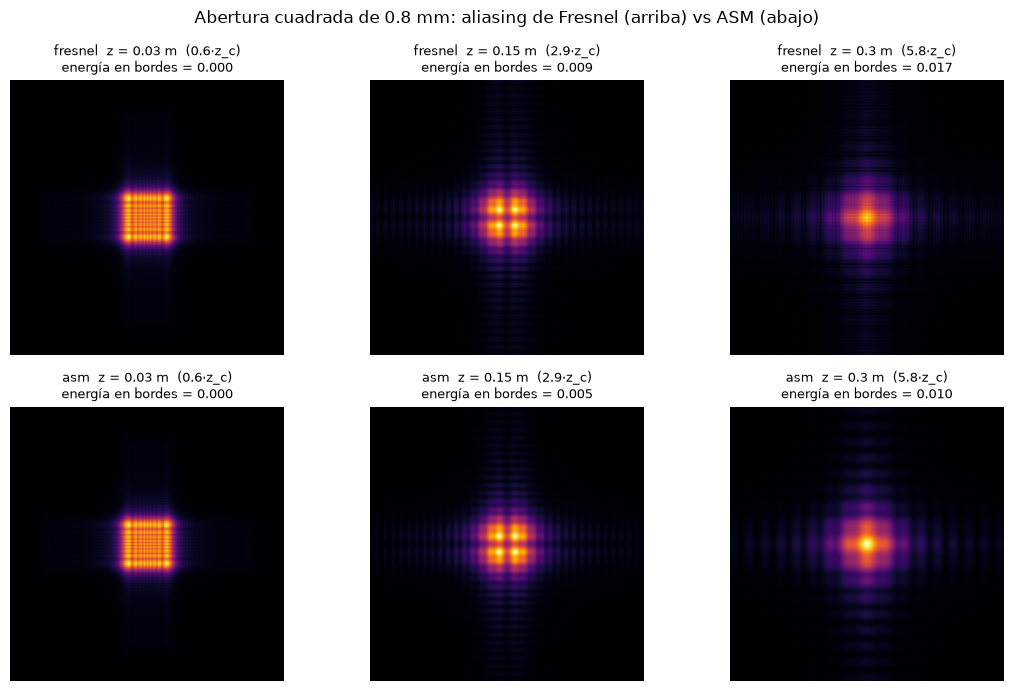

Diagnóstico para Fresnel a 0.3 m: ['E03']


In [20]:
u_sq = campo_inicial("cuadrada", N, dx, 0.8e-3)
zc = N * dx**2 / wl
fig, ejes = plt.subplots(2, 3, figsize=(11, 7))
for k, z in enumerate([0.03, 0.15, 0.3]):
    for fila, metodo in enumerate(["fresnel", "asm"]):
        u_z = propagar(u_sq, wl, dx, z, metodo)
        I, m = u_z.abs()**2, metricas(u_sq, u_z, dx)
        ejes[fila, k].imshow(I.numpy() ** 0.5, cmap="inferno")
        ejes[fila, k].set_title(f"{metodo}  z = {z} m  ({z/zc:.1f}·z_c)\nenergía en bordes = {m['fraccion_energia_bordes']:.3f}", fontsize=9)
        ejes[fila, k].axis("off")
plt.suptitle("Abertura cuadrada de 0.8 mm: aliasing de Fresnel (arriba) vs ASM (abajo)"); plt.tight_layout(); plt.show()
print("Diagnóstico para Fresnel a 0.3 m:", [h["id"] for h in diagnosticar(wl, dx, N, 0.3, "fresnel")]); SESION["hallazgos"].clear()

In [21]:
# Lente (ASMtf): el primer cero del patrón de Airy debe estar en r1 = 1.22 λ f / D
D, f = 1e-3, 0.2
U = lente_tf(campo_inicial("circular", N, dx, D), wl, dx, f)
I = (U.abs()**2).numpy(); perfil = I[N // 2, N // 2:]
r1_teo = 1.22 * wl * f / D
r1_num = primer_minimo(perfil) * dx
print(f"Primer cero de Airy: teoría {r1_teo*1e6:.1f} µm, simulación {r1_num*1e6:.1f} µm  (resolución dx = {dx*1e6:.0f} µm)")

# L2: N impar en ASMprop: la librería no da error, pero la malla de frecuencias es incorrecta
with precision64():
    for n in (256, 255):
        P = pz.ASMprop(NS(z=0.02, wl=wl, dx=dx, dy=dx, sx=n, sy=n))
        marg = math.ceil(0.02 * math.tan(math.asin(wl / (2 * dx))) / dx)
        print(f"N = {n}: Prop.shape = {tuple(P.shape)}, esperado ≈ {n + 2*marg}")

Primer cero de Airy: teoría 154.5 µm, simulación 152.0 µm  (resolución dx = 8 µm)
N = 256: Prop.shape = (455, 455), esperado ≈ 454
N = 255: Prop.shape = (339, 339), esperado ≈ 453


## 4. Herramientas que el LLM puede llamar

Todas devuelven JSON. El LLM decide cuándo llamar a la librería, porque no toda pregunta necesita simular.

| Herramienta | Qué hace |
|---|---|
| `diagnosticar_parametros` | Revisa λ, dx, N, z y el método antes de simular |
| `simular_propagacion` | Diagnostica, propaga con `pyavzutilsV2`, mide y guarda una figura |
| `transformada_lente` | Patrón en el plano focal con `pz.ASMtf`, comparado con Airy cuando la abertura es circular |
| `revisar_codigo` | Busca errores conocidos en un fragmento de código: patrones de la base, unidades literales y z frente a z_c |
| `consultar_errores` | Busca en la base de errores por síntomas o tema |
| `registrar_error` | Propone una lección nueva para la base, que se valida antes de guardarse |
| `calcular` | Cuentas con numpy, para no inventar números |

In [22]:
def _js(x): return json.dumps(x, ensure_ascii=False, default=float)

def diagnosticar_parametros(wl_m: float, dx_m: float, N: int, z_m: float, metodo: str = "asm", tamano_objeto_m: float = 0.0) -> str:
    """Revisa los parámetros de una simulación de propagación ANTES de ejecutarla. Todas las longitudes en metros.
    wl_m: longitud de onda; dx_m: tamaño de píxel; N: píxeles por lado; z_m: distancia de propagación;
    metodo: 'asm' (espectro angular) o 'fresnel' (función de transferencia de Fresnel); tamano_objeto_m: tamaño del objeto (0 si no aplica).
    Devuelve la lista de problemas encontrados, con su id en la base de errores, detalle y solución."""
    h = diagnosticar(float(wl_m), float(dx_m), int(N), float(z_m), metodo, tamano=float(tamano_objeto_m) or None)
    return _js({"problemas": h, "z_c_fresnel_m": int(N) * float(dx_m)**2 / float(wl_m)} if h else
               {"problemas": [], "mensaje": "Sin problemas detectados.", "z_c_fresnel_m": int(N) * float(dx_m)**2 / float(wl_m)})

def simular_propagacion(fuente: str, tamano_m: float, wl_m: float, dx_m: float, N: int, z_m: float, metodo: str = "asm") -> str:
    """Simula la propagación de un campo con la librería pyavzutilsV2 y devuelve métricas. Longitudes en metros.
    fuente: 'gauss' (tamano_m = cintura w0), 'circular' (diámetro), 'cuadrada' (lado) o 'doble_rendija' (separación).
    metodo: 'asm' o 'fresnel'. Devuelve energía relativa, fracción de energía en los bordes (aliasing/wrap-around),
    ancho rms, número de Fresnel, comparación con la teoría si es gaussiano, problemas detectados y la ruta de la figura."""
    wl, dx, N, z = float(wl_m), float(dx_m), int(N), float(z_m)
    problemas = diagnosticar(wl, dx, N, z, metodo, tamano=float(tamano_m))
    if any(p["id"] in ("E02", "E06") for p in problemas) and metodo == "asm":
        return _js({"error": "No se simuló: parámetros incompatibles con ASMprop.", "problemas": problemas})
    u0 = campo_inicial(fuente, N, dx, float(tamano_m))
    u = propagar(u0, wl, dx, z, metodo)
    m = metricas(u0, u, dx)
    a = float(tamano_m) / 2
    m["numero_fresnel"] = a**2 / (wl * abs(z)) if z else None
    if fuente == "gauss":
        w0 = float(tamano_m); wz = w0 * np.sqrt(1 + (z * wl / (np.pi * w0**2))**2)
        m["ancho_teorico_m"] = wz; m["error_ancho_%"] = 100 * (m["ancho_rms_m"] / wz - 1)
    if abs(m["energia_relativa"] - 1) > 0.01:
        _hallazgo(problemas, "E09", f"energía relativa = {m['energia_relativa']}" +
                  (" (en ASM la energía difractada fuera de la ventana se recorta al quitar el padding)" if metodo == "asm" else ""),
                  "advertencia"); SESION["hallazgos"].append(problemas[-1])
    if m["fraccion_energia_bordes"] > 0.01:
        _hallazgo(problemas, "E12" if metodo == "asm" else "E03", f"{100*m['fraccion_energia_bordes']:.1f} % de la energía en los bordes",
                  "advertencia"); SESION["hallazgos"].append(problemas[-1])
    ruta = CARPETA / f"prop_{fuente}_{metodo}_z{z:g}.png"
    fig, ej = plt.subplots(1, 2, figsize=(8, 3.6))
    ext = [-N*dx/2e-3, N*dx/2e-3, -N*dx/2e-3, N*dx/2e-3]
    ej[0].imshow((u0.abs()**2).numpy(), cmap="gray", extent=ext); ej[0].set_title("Entrada |u|²"); ej[0].set_xlabel("mm")
    ej[1].imshow((u.abs()**2).numpy() ** 0.5, cmap="inferno", extent=ext); ej[1].set_title(f"{metodo}, z = {z:g} m (√I)"); ej[1].set_xlabel("mm")
    plt.tight_layout(); fig.savefig(ruta, dpi=110); plt.close(fig)
    return _js({"metricas": m, "problemas": problemas, "figura": str(ruta)})

def transformada_lente(diametro_m: float, f_m: float, wl_m: float, dx_m: float, N: int) -> str:
    """Calcula con pz.ASMtf el patrón en el plano focal de una lente de focal f_m iluminada a través de una
    abertura circular de diámetro diametro_m (longitudes en metros). Compara el primer cero con Airy (1.22 λ f / D)."""
    D, f, wl, dx, N = map(float, (diametro_m, f_m, wl_m, dx_m, N)); N = int(N)
    problemas = diagnosticar(wl, dx, N, f, "asm", tamano=D)
    if any(p["id"] in ("E02", "E06") for p in problemas):
        return _js({"error": "Parámetros incompatibles con ASMprop.", "problemas": problemas})
    I = (lente_tf(campo_inicial("circular", N, dx, D), wl, dx, f).abs()**2).numpy()
    r1_teo = 1.22 * wl * f / D
    perfil = I[N // 2, N // 2:]
    r1 = primer_minimo(perfil) * dx
    return _js({"r1_teorico_m": r1_teo, "r1_simulado_m": float(r1), "pixeles_en_r1": r1_teo / dx,
                "problemas": problemas, "aviso": "Si pixeles_en_r1 < 5 el patrón está submuestreado." if r1_teo / dx < 5 else ""})

def revisar_codigo(codigo: str) -> str:
    """Revisa un fragmento de código Python de óptica en busca de errores comunes: patrones de la base de errores
    (incluidos los aprendidos), unidades sospechosas en wl/dx y propagación de Fresnel más allá de z_c.
    Devuelve una lista de hallazgos con línea, id del error y solución."""
    h = []
    lineas = codigo.splitlines()
    for e in BASE.errores:
        if not e.get("patron"): continue
        for i, l in enumerate(lineas, 1):
            if re.search(e["patron"], l):
                h.append({"linea": i, "codigo": l.strip(), "id": e["id"], "titulo": e["titulo"], "solucion": e["solucion"]})
                BASE.marcar_detectado(e["id"]); break
    def valor(nombre):
        m = re.search(rf"\b{nombre}\s*=\s*([0-9.]+(?:[eE][-+]?\d+)?)", codigo)
        return float(m.group(1)) if m else None
    wl, dx, z, N = valor("wl"), valor("dx"), valor("z"), valor("N")
    for nombre, v, lo, hi in (("wl", wl, 1e-7, 2e-5), ("dx", dx, 1e-7, 1e-3)):
        if v is not None and not (lo <= v <= hi):
            h.append({"linea": None, "codigo": f"{nombre} = {v:g}", "id": "E01", "titulo": BASE.get("E01")["titulo"],
                      "solucion": BASE.get("E01")["solucion"]}); BASE.marcar_detectado("E01")
    if "propft" in codigo and None not in (wl, dx, z, N) and wl > 0 and z > N * dx**2 / wl:
        h.append({"linea": None, "codigo": f"z = {z:g} > z_c = {N*dx**2/wl:.3g}", "id": "E03",
                  "titulo": BASE.get("E03")["titulo"], "solucion": BASE.get("E03")["solucion"]})
    SESION["hallazgos"] += [{"id": x["id"], "titulo": x["titulo"], "severidad": "error", "detalle": x["codigo"], "solucion": x["solucion"]} for x in h]
    return _js({"hallazgos": h} if h else {"hallazgos": [], "mensaje": "No se encontraron patrones conocidos (eso no garantiza que el código esté bien)."})

def consultar_errores(consulta: str) -> str:
    """Busca en la base de errores comunes de óptica computacional los más relevantes para una descripción
    de síntomas o tema (por ejemplo 'anillos falsos a distancias grandes'). Devuelve id, título, causa y solución."""
    r = BASE.consultar(consulta, k=4)
    return _js([{k: e[k] for k in ("id", "titulo", "sintomas", "causa", "solucion")} for e in r] or {"mensaje": "Nada relevante en la base."})

def registrar_error(titulo: str, sintomas: str, causa: str, solucion: str, palabras_clave: str, patron: str = "") -> str:
    """Registra en la base un error de óptica computacional NUEVO que hayas identificado (que no esté en la base).
    patron: expresión regular opcional que detecte el error en una línea de código. Devuelve el id asignado o el motivo del rechazo."""
    ok, msg = BASE.registrar(titulo, sintomas, causa, solucion, palabras_clave, patron or None)
    return _js({"registrado": ok, "id" if ok else "motivo": msg})

def calcular(expresion: str) -> str:
    """Evalúa una expresión numérica con numpy (np) y pi, por ejemplo '512*(8e-6)**2/633e-9' o '1.22*633e-9*0.2/1e-3'."""
    try:
        return _js({"expresion": expresion, "resultado": eval(expresion, {"__builtins__": {}}, {"np": np, "pi": np.pi})})
    except Exception as exc:
        return _js({"error": str(exc)})

HERRAMIENTAS = [diagnosticar_parametros, simular_propagacion, transformada_lente, revisar_codigo,
                consultar_errores, registrar_error, calcular]

In [23]:
# Prueba de las herramientas a mano (sin LLM)
print(simular_propagacion("circular", 1e-3, 633e-9, 8e-6, 512, 0.2, "fresnel"))
codigo_prueba = """
wl = 633e-6
dx = 8e-6; N = 512; z = 0.5
H = pz.propft(args)
I = np.abs(u)
A = pz.ASMtf(u, args)
"""
print(json.dumps(json.loads(revisar_codigo(codigo_prueba)), ensure_ascii=False, indent=1))
SESION["hallazgos"].clear()

{"metricas": {"energia_relativa": 1.0, "fraccion_energia_bordes": 0.0107, "ancho_rms_m": 0.0006503558604354374, "hay_nan": false, "numero_fresnel": 1.9747235387045812}, "problemas": [{"id": "E03", "titulo": "Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ)", "severidad": "error", "detalle": "z = 0.2 m > z_c = N·dx²/λ = 0.0518 m (factor 3.9).", "solucion": "Para z > z_c usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z."}, {"id": "E03", "titulo": "Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ)", "severidad": "advertencia", "detalle": "1.1 % de la energía en los bordes", "solucion": "Para z > z_c usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z."}], "figura": "salidas_agente_optica\\prop_circular_fresnel_z0.2.png"}
{
 "hallazgos": [
  {
   "linea": 4,
   "codigo": "H = pz.propft(args)",
   "id": "E03",
   "titulo": "Aliasing de la funció

## 5. El agente

Una petición recorre este flujo:

1. **Recuperar memoria**: busca en la base los errores más relevantes para la petición y los pone en el *system prompt*.
2. **Ciclo de herramientas**: el LLM diagnostica, simula si hace falta, revisa el código o consulta la base. Es el mismo ciclo del reto 2.
3. **Revisión (reflexión)**:
   - Automática: cada error que detectaron las herramientas debe aparecer en la respuesta con su id (`[E03]`). Si falta alguno, la respuesta se rechaza.
   - LLM: un revisor de óptica comprueba que los números vengan de las herramientas y que la respuesta tenga sentido físico.
4. **Aprender**: un paso final le pide al LLM que diga si en la sesión apareció un error **que no está en la base**. Si es así, lo registra con `BaseErrores.registrar`, que lo valida y rechaza los duplicados. Tus comentarios (`comentario_usuario`) también entran aquí.

In [24]:
import ollama

def chat(messages, tools=None, model=MODELO):
    return ollama.chat(model=model, messages=messages, tools=tools, options={"temperature": 0.2})

def contenido(msg):
    c = msg.get("content") if isinstance(msg, dict) else msg.content
    return re.sub(r"<think>.*?</think>", "", c or "", flags=re.S).strip()

def _campo(obj, k):
    return obj.get(k) if isinstance(obj, dict) else getattr(obj, k, None)

def ciclo_herramientas(system_prompt, peticion, tools, max_turnos=8, model=MODELO, mensajes_previos=None):
    por_nombre = {t.__name__: t for t in tools}
    messages = mensajes_previos or [{"role": "system", "content": system_prompt}, {"role": "user", "content": peticion}]
    for _ in range(max_turnos):
        mensaje = chat(messages, tools=tools, model=model)["message"]
        messages.append(mensaje)
        llamadas = _campo(mensaje, "tool_calls")
        if not llamadas: break
        for call in llamadas:
            fn = _campo(call, "function"); nombre = _campo(fn, "name"); args = _campo(fn, "arguments") or {}
            if isinstance(args, str):
                try: args = json.loads(args)
                except json.JSONDecodeError: args = {}
            f = por_nombre.get(nombre)
            try: res = f(**args) if f else _js({"error": f"herramienta '{nombre}' no existe"})
            except Exception as exc: res = _js({"error": f"{type(exc).__name__}: {exc}"})
            messages.append({"role": "tool", "content": str(res), "name": nombre})
    return messages

def imprimir_traza(messages):
    for m in messages:
        rol = _campo(m, "role")
        if rol == "tool":
            print(f"   🔧 {m['name']} →", textwrap.shorten(m["content"], 220))
        elif rol == "assistant":
            for c in (_campo(m, "tool_calls") or []):
                fn = _campo(c, "function")
                print(f"   🤖 {_campo(fn, 'name')}({json.dumps(_campo(fn, 'arguments'), ensure_ascii=False)[:160]})")

In [25]:
SISTEMA_OPTICA = """\
Eres un asistente experto en óptica física computacional (difracción escalar, propagación por espectro angular (ASM)
y Fresnel, transformadas con lentes). Tienes herramientas que usan la librería pyavzutilsV2.
Reglas:
1. Antes de simular, llama a diagnosticar_parametros. Si hay problemas, explícalos y, si puedes, propón y simula parámetros corregidos.
2. Solo simula (simular_propagacion, transformada_lente) si la petición lo necesita; para preguntas conceptuales usa consultar_errores.
3. Si te dan código, llama a revisar_codigo y luego razona sobre lo que la herramienta no detecta.
4. Todos los números deben venir de las herramientas o de calcular. Trabaja en metros.
5. Cita cada error de la base por su id entre corchetes, por ejemplo [E03], e incluye su solución.
Responde en español, de forma breve y concreta.

ERRORES CONOCIDOS MÁS RELEVANTES PARA ESTA PETICIÓN (memoria del agente):
{lecciones}
"""

REVISOR_OPTICA = """\
Eres un revisor de óptica computacional. Te dan una petición, los problemas detectados por las herramientas y una respuesta.
Verifica: (a) que los números citados vengan de las herramientas; (b) que la física sea correcta (unidades, régimen
de Fresnel/ASM, intensidad vs amplitud); (c) que responda la petición.
Responde EXACTAMENTE en dos líneas:
APROBADO: si/no
COMENTARIOS: <qué corregir o "Ninguno">
"""

APRENDIZ_OPTICA = """\
Eres el módulo de aprendizaje de un agente de óptica. Te dan el resumen de una sesión (petición, hallazgos,
respuesta y comentario del usuario) y la lista de títulos de errores que YA están en la base.
Si en la sesión apareció un error de óptica computacional que NO está en la base, descríbelo. Si no, responde {"nuevo": false}.
Responde SOLO un JSON:
{"nuevo": true, "titulo": "...", "sintomas": "...", "causa": "...", "solucion": "...", "palabras_clave": "palabras separadas por espacio",
 "patron": "regex opcional que detecte el error en una línea de código, o cadena vacía"}
"""

def _lecciones(peticion, codigo):
    rel = BASE.consultar(peticion + " " + (codigo or ""), k=5)
    return "\n".join(f"- [{e['id']}] {e['titulo']}: {e['solucion']}" for e in rel) or "- (ninguno)"

def revision_automatica(respuesta):
    faltan = sorted({h["id"] for h in SESION["hallazgos"] if h.get("severidad") == "error"} - set(re.findall(r"\[([EA]\d{2})\]", respuesta)))
    return faltan

def aprender(peticion, respuesta, comentario_usuario, model):
    resumen = {"peticion": peticion, "hallazgos": [(h["id"], h["detalle"]) for h in SESION["hallazgos"]],
               "respuesta": respuesta[:1500], "comentario_usuario": comentario_usuario or ""}
    titulos = "\n".join(f"- {e['id']}: {e['titulo']}" for e in BASE.errores)
    texto = contenido(chat([{"role": "system", "content": APRENDIZ_OPTICA},
                            {"role": "user", "content": f"SESIÓN:\n{_js(resumen)}\n\nYA EN LA BASE:\n{titulos}"}], model=model)["message"])
    try:
        prop = json.loads(re.search(r"\{.*\}", texto, re.S).group(0))
    except Exception:
        return {"nuevo": False, "motivo": "respuesta del aprendiz no es JSON"}
    if not prop.get("nuevo"):
        return {"nuevo": False}
    ok, msg = BASE.registrar(prop.get("titulo", ""), prop.get("sintomas", ""), prop.get("causa", ""),
                             prop.get("solucion", ""), prop.get("palabras_clave", ""), prop.get("patron") or None)
    return {"nuevo": ok, "id" if ok else "motivo": msg, "titulo": prop.get("titulo")}

def agente_optica(peticion, codigo=None, comentario_usuario=None, model=MODELO, max_rondas=2, verbose=True):
    SESION["hallazgos"] = []
    t0 = time.time()
    lecciones = _lecciones(peticion, codigo)
    if verbose: print("🧠 MEMORIA RECUPERADA\n" + textwrap.indent(lecciones, "   "))
    texto_usuario = peticion + (f"\n\nCÓDIGO A REVISAR:\n```python\n{codigo}\n```" if codigo else "")
    msgs = ciclo_herramientas(SISTEMA_OPTICA.format(lecciones=lecciones), texto_usuario, HERRAMIENTAS, model=model)
    if verbose: print("\n🔎 HERRAMIENTAS"); imprimir_traza(msgs[2:])
    respuesta = contenido(msgs[-1])
    revisiones = []
    for ronda in range(max_rondas + 1):
        faltan = revision_automatica(respuesta)
        rev = contenido(chat([{"role": "system", "content": REVISOR_OPTICA},
                              {"role": "user", "content": f"PETICIÓN: {texto_usuario}\n\nHALLAZGOS: {_js(SESION['hallazgos'])}\n\nRESPUESTA:\n{respuesta}"}],
                             model=model)["message"])
        aprobado = bool(re.search(r"aprobado:\s*s[ií]", rev, re.I)) and not faltan
        if faltan:
            rev += f"\nVERIFICACIÓN AUTOMÁTICA: la respuesta no menciona los errores detectados {faltan}. Explícalos con su id y solución."
        revisiones.append({"ronda": ronda, "aprobado": aprobado, "comentarios": rev, "respuesta": respuesta})
        if verbose: print(f"\n🧐 REVISIÓN {ronda}: {'aprobada ✔' if aprobado else 'rechazada ✘'}  {textwrap.shorten(rev, 220)}")
        if aprobado or ronda == max_rondas: break
        msgs.append({"role": "user", "content": f"Un revisor pide corregir la respuesta:\n{rev}\nEscribe la respuesta corregida completa."})
        msgs = ciclo_herramientas(None, None, HERRAMIENTAS, model=model, mensajes_previos=msgs)
        respuesta = contenido(msgs[-1])
    aprendizaje = aprender(peticion, respuesta, comentario_usuario, model)
    if verbose: print(f"\n📚 APRENDIZAJE: {aprendizaje}")
    ruta = CARPETA / f"respuesta_{time.strftime('%Y%m%d_%H%M%S')}_{int(time.time()*1000)%1000:03d}.md"
    ruta.write_text(f"# Petición\n{texto_usuario}\n\n# Respuesta\n{respuesta}\n\n# Hallazgos\n{_js(SESION['hallazgos'])}\n", encoding="utf-8")
    if verbose: print(f"💾 Guardado en {ruta} ({time.time()-t0:.0f} s)")
    return {"respuesta": respuesta, "hallazgos": list(SESION["hallazgos"]), "revisiones": revisiones,
            "aprendizaje": aprendizaje, "ruta": str(ruta)}

## 6. Usar el agente con Ollama

Las celdas marcadas con ⚠️ necesitan Ollama corriendo (`ollama list`). Con `qwen3:1.7b` en CPU cada petición tarda de 1 a 5 minutos.

In [26]:
CONTAR_DETECCIONES = True      # desde aquí las detecciones sí se cuentan en tu base
# ⚠️ OLLAMA
print(ollama.list())

models=[Model(model='qwen2.5:3b', modified_at=datetime.datetime(2026, 9, 22, 17, 48, 51, 997641, tzinfo=TzInfo(-18000)), digest='357c53fb659c5076de1d65ccb0b397446227b71a42be9d1603d46168015c9e4b', size=1929912432, details=ModelDetails(parent_model='', format='gguf', family='qwen2', families=['qwen2'], parameter_size='3.1B', quantization_level='Q4_K_M')), Model(model='llama3.2:1b', modified_at=datetime.datetime(2026, 8, 18, 21, 27, 20, 83087, tzinfo=TzInfo(-18000)), digest='baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878', size=1321098329, details=ModelDetails(parent_model='', format='gguf', family='llama', families=['llama'], parameter_size='1.2B', quantization_level='Q8_0'))]


In [27]:
# ⚠️ OLLAMA — Ejemplo 1: simulación con diagnóstico
r1 = agente_optica("Simula la difracción de una abertura circular de 1 mm iluminada con un láser de 633 nm "
                   "a 20 cm, con N = 512 y dx = 8 µm, usando Fresnel. ¿Es confiable el resultado?")
from IPython.display import Markdown, display, Image
display(Markdown(r1["respuesta"]))

🧠 MEMORIA RECUPERADA
   - [E01] Unidades mezcladas (mm, µm y m): Trabajar todo en metros: λ ~ 1e-7–2e-5 m, dx ~ 1e-7–1e-3 m. Definir constantes um=1e-6, mm=1e-3.
   - [E06] N impar en ASMprop (malla de frecuencias incorrecta): Usar N par (rellenar con una fila/columna de ceros).
   - [E08] Fuera del régimen paraxial (aproximación de Fresnel): Usar ASM (exacta para ondas escalares) a distancias cortas.
   - [E11] ASMtf/ASMitf modifican args.z: Pasar una copia: pz.ASMtf(A, copy.copy(args)), con sx, sy iguales a A.shape.
   - [E03] Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ): Para z > z_c usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z.

🔎 HERRAMIENTAS
   🤖 revisar_codigo({"codigo": "from pyavzutilsV2 import *; from pyavzutilsV2 import *; A = transformada_lente(diametro_m=0.001, f_m=0.2, wl_m=633e-9, dx_m=8e-6, N=512); print(A)"})
   🔧 revisar_codigo → {"hallazgos": [], "mensaje": "No se encontraron patrones

El resultado de la simulación tiene algunos problemas:

1. [E03] Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ): z = 0.2 m > z_c = N·dx²/λ = 0.0518 m (factor 3.9). Para z > z_c, se recomienda usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z.

2. [E03] Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ): 1.1 % de la energía en los bordes. Para z > z_c, se recomienda usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z.

Para corregir estos problemas, vamos a aumentar N (padding) para que z_c > z. Simularé nuevamente con N = 1024.

In [28]:
# ⚠️ OLLAMA — Ejemplo 2: revisión de tu propio código
mi_codigo = """
wl = 633e-6          # longitud de onda
dx = 8e-6; N = 512; z = 1.0
args = NS(z=z, wl=wl, dx=dx, sx=N, sy=N)
H = pz.propft(args)
u2 = pz.convprop(u1, H)
I = np.abs(u2)
fase = torch.angle(u2)
"""
r2 = agente_optica("Revisa mi código de propagación: el patrón me sale raro y la fase tiene saltos.", codigo=mi_codigo,
                   comentario_usuario="Los saltos de fase eran por no desenvolver la fase con np.unwrap.")
display(Markdown(r2["respuesta"]))

🧠 MEMORIA RECUPERADA
   - [E03] Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ): Para z > z_c usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z.
   - [E01] Unidades mezcladas (mm, µm y m): Trabajar todo en metros: λ ~ 1e-7–2e-5 m, dx ~ 1e-7–1e-3 m. Definir constantes um=1e-6, mm=1e-3.
   - [E02] Muestreo sub-longitud de onda en ASM (dx < λ/2): Usar dx ≥ λ/2 o reescribir el propagador con sqrt compleja y sin el margen por asin.
   - [E11] ASMtf/ASMitf modifican args.z: Pasar una copia: pz.ASMtf(A, copy.copy(args)), con sx, sy iguales a A.shape.
   - [E15] fftshift/ifftshift con N impar: Usar N par o ifftshift antes de fft2 y fftshift después de ifft2.

🔎 HERRAMIENTAS

🧐 REVISIÓN 0: aprobada ✔  APROBADO: si COMENTARIOS: Ninguno. Tu código parece estar correctamente estructurado para la propagación de ondas en un sistema de óptica computacional. Sin datos específicos de `u1` y `pz.propft`, no puedo [...]

📚 APREND

In [29]:
# ⚠️ OLLAMA — Retroalimentación: dile al agente si una detección te sirvió (sube o baja su prioridad)
# BASE.retroalimentar("E03", util=True)
# BASE.retroalimentar("E08", util=False)
for e in BASE.errores:
    print(f"{e['id']:>4} {e['origen']:>9}  detectado {e['veces_detectado']:>2}×  confianza {e['confianza']:.2f}  {e['titulo']}")

 E01   semilla  detectado  0×  confianza 1.00  Unidades mezcladas (mm, µm y m)
 E02   semilla  detectado  0×  confianza 1.00  Muestreo sub-longitud de onda en ASM (dx < λ/2)
 E03   semilla  detectado  2×  confianza 1.00  Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ)
 E04   semilla  detectado  0×  confianza 1.00  Precisión float32 en ASM
 E05   semilla  detectado  0×  confianza 1.00  Padding enorme en ASMprop
 E06   semilla  detectado  0×  confianza 1.00  N impar en ASMprop (malla de frecuencias incorrecta)
 E07   semilla  detectado  0×  confianza 1.00  Píxeles rectangulares (dx ≠ dy) en ASMprop / ASMtf
 E08   semilla  detectado  0×  confianza 1.00  Fuera del régimen paraxial (aproximación de Fresnel)
 E09   semilla  detectado  0×  confianza 1.00  Energía no conservada
 E10   semilla  detectado  0×  confianza 1.00  Confundir amplitud con intensidad
 E11   semilla  detectado  0×  confianza 1.00  ASMtf/ASMitf modifican args.z
 E12   semilla  detectado  0×  confianza 1.0

## 7. Experimentos propuestos

1. **Aprendizaje acumulado.** Corre el ejemplo 2 y después pide revisar otro código que use `np.angle` sin desenvolver. Si el aprendiz registró la lección con un patrón, `revisar_codigo` la detecta sola en la segunda sesión.
2. **Retroalimentación.** Marca `E08` como no útil tres veces y verifica con `BASE.consultar("fresnel distancia")` que baja en la lista.
3. **Con y sin memoria.** Reemplaza `_lecciones` por una función que devuelva `"- (ninguno)"` y compara cuántos errores menciona el modelo sin las pistas.
4. **Tus propios errores.** Agrega a `ERRORES_SEMILLA` los errores que te hayan pasado en el laboratorio de óptica, por ejemplo con el modulador espacial (SLM), los píxeles de la cámara o la calibración de la escala, y borra `errores_optica.json` para regenerar la base.
5. **Nuevas herramientas.** Agrega `holograma_gs(...)` usando `pz.Ifrta` (Gerchberg–Saxton) y un diagnóstico propio, por ejemplo que `Ifrta` supone `sx = sy`.

## Apéndice: prueba del flujo completo con un LLM simulado

Para comprobar la lógica sin Ollama, reemplazamos `ollama.chat` por un guion fijo. **Las herramientas sí son reales**: diagnóstico, simulación con `pyavzutilsV2`, revisión de código y base de errores. La prueba usa una copia temporal de la base para no ensuciar la tuya. Comprueba tres cosas:

1. El revisor automático rechaza una respuesta que omite un error detectado ([E03]) y el agente la corrige.
2. El aprendiz registra una lección nueva, la fase envuelta, con su patrón.
3. En la sesión siguiente, `revisar_codigo` detecta ese error **sin ayuda del LLM**, gracias a lo aprendido.

In [30]:
class OllamaSimulado:
    def __init__(self): self.n = 0
    def _llamar(self, nombre, **a): return {"message": {"role": "assistant", "content": "", "tool_calls": [{"function": {"name": nombre, "arguments": a}}]}}
    def _texto(self, t): return {"message": {"role": "assistant", "content": t}}
    def chat(self, model, messages, tools=None, options=None):
        sistema = messages[0]["content"] if messages else ""
        if sistema.startswith("Eres un revisor"):
            return self._texto("APROBADO: si\nCOMENTARIOS: Ninguno")
        if sistema.startswith("Eres el módulo de aprendizaje"):
            s = messages[-1]["content"]
            if "unwrap" in s and "fase envuelta" not in s.lower():
                return self._texto(json.dumps({"nuevo": True, "titulo": "Fase envuelta sin desenvolver",
                    "sintomas": "Saltos de 2π en mapas o perfiles de fase; derivadas de fase enormes.",
                    "causa": "torch.angle/np.angle devuelven la fase en (-π, π]; restar o derivar fases envueltas crea discontinuidades.",
                    "solucion": "Desenvolver con np.unwrap (1D) o skimage.restoration.unwrap_phase (2D) antes de analizar la fase.",
                    "palabras_clave": "fase envuelta unwrap angle saltos discontinuidad desenvolver",
                    "patron": r"\b(torch|np)\.angle\s*\("}))
            return self._texto('{"nuevo": false}')
        # agente principal: guion según la petición y lo que ya pasó
        usuario = messages[1]["content"]; ult = messages[-1]; rol_ult = _campo(ult, "role")
        herramientas_usadas = [m["name"] for m in messages if _campo(m, "role") == "tool"]
        corrige = any(_campo(m, "role") == "user" and "revisor pide" in m["content"] for m in messages)
        if "abertura circular" in usuario:
            if "diagnosticar_parametros" not in herramientas_usadas:
                return self._llamar("diagnosticar_parametros", wl_m=633e-9, dx_m=8e-6, N=512, z_m=0.2, metodo="fresnel", tamano_objeto_m=1e-3)
            if herramientas_usadas.count("simular_propagacion") == 0:
                return self._llamar("simular_propagacion", fuente="circular", tamano_m=1e-3, wl_m=633e-9, dx_m=8e-6, N=512, z_m=0.2, metodo="fresnel")
            if herramientas_usadas.count("simular_propagacion") == 1:
                return self._llamar("simular_propagacion", fuente="circular", tamano_m=1e-3, wl_m=633e-9, dx_m=8e-6, N=512, z_m=0.2, metodo="asm")
            if not corrige:   # primera versión: olvida mencionar el aliasing (para probar la reflexión)
                return self._texto("Simulé la abertura con Fresnel y con ASM; el patrón muestra anillos de difracción.")
            sim = [json.loads(m["content"]) for m in messages if _campo(m, "role") == "tool" and m["name"] == "simular_propagacion"]
            return self._texto(f"El resultado con Fresnel **no es confiable** [E03]: z = 0.2 m supera z_c = 0.052 m y "
                f"{100*sim[0]['metricas']['fraccion_energia_bordes']:.1f} % de la energía aparece en los bordes. "
                f"Con ASM (float64) la fracción en los bordes es {100*sim[1]['metricas']['fraccion_energia_bordes']:.1f} %. "
                "Solución: usar ASM o aumentar N para que z_c > z.")
        if "CÓDIGO A REVISAR" in usuario:
            if "revisar_codigo" not in herramientas_usadas:
                return self._llamar("revisar_codigo", codigo=usuario.split("```python")[1].split("```")[0])
            res = json.loads([m for m in messages if _campo(m, "role") == "tool"][-1]["content"])
            ids = sorted({h["id"] for h in res["hallazgos"]})
            return self._texto("Encontré: " + "; ".join(f"[{h['id']}] {h['titulo']} (línea {h['linea'] or '-'}): {h['solucion']}" for h in res["hallazgos"])
                               + (". Además, la fase se calcula sin desenvolver." if "A01" not in ids else "."))
        return self._texto("ok")

# usar una base temporal para la prueba
_BASE_REAL, _ollama_real = BASE, ollama
_contar_real = CONTAR_DETECCIONES; CONTAR_DETECCIONES = True
BASE = BaseErrores(CARPETA / "base_prueba.json")
if BASE.ruta.exists(): BASE.ruta.unlink(); BASE = BaseErrores(CARPETA / "base_prueba.json")
ollama = OllamaSimulado()
try:
    print("=" * 30, "SESIÓN 1: simulación", "=" * 30)
    s1 = agente_optica("Simula la difracción de una abertura circular de 1 mm iluminada con un láser de 633 nm "
                       "a 20 cm, con N = 512 y dx = 8 µm, usando Fresnel. ¿Es confiable el resultado?", model="simulado")
    print("\nRespuesta final:", s1["respuesta"])

    print("\n" + "=" * 30, "SESIÓN 2: revisión de código + comentario", "=" * 30)
    cod2 = "wl = 633e-6\ndx = 8e-6; N = 512; z = 1.0\nH = pz.propft(args)\nI = np.abs(u2)\nfase = torch.angle(u2)"
    s2 = agente_optica("Revisa mi código: la fase tiene saltos.", codigo=cod2,
                       comentario_usuario="Los saltos de fase eran por no desenvolver la fase con np.unwrap.", model="simulado")
    print("\nRespuesta final:", s2["respuesta"])

    print("\n" + "=" * 30, "SESIÓN 3: código nuevo con el mismo error", "=" * 30)
    cod3 = "wl = 532e-9\ndx = 4e-6\nphi = np.angle(campo)\ngrad = np.diff(phi)"
    s3 = agente_optica("Revisa este análisis de fase.", codigo=cod3, model="simulado")
    print("\nRespuesta final:", s3["respuesta"])
finally:
    BASE_PRUEBA, BASE, ollama = BASE, _BASE_REAL, _ollama_real
    CONTAR_DETECCIONES = _contar_real

print("\n--- Verificaciones ---")
print("1. Sesión 1 rechazada en la ronda 0 y aprobada después:", [(r["ronda"], r["aprobado"]) for r in s1["revisiones"]])
print("2. Lección aprendida en la sesión 2:", s2["aprendizaje"])
print("3. En la sesión 3, revisar_codigo detectó A01 por su patrón:", any(h["id"] == "A01" for h in s3["hallazgos"]))
print("   Base de prueba:", len(BASE_PRUEBA.errores), "errores;", [e["id"] for e in BASE_PRUEBA.errores if e["origen"] == "aprendido"], "aprendidos")

============================== SESIÓN 1: simulación ==============================
🧠 MEMORIA RECUPERADA
   - [E01] Unidades mezcladas (mm, µm y m): Trabajar todo en metros: λ ~ 1e-7–2e-5 m, dx ~ 1e-7–1e-3 m. Definir constantes um=1e-6, mm=1e-3.
   - [E06] N impar en ASMprop (malla de frecuencias incorrecta): Usar N par (rellenar con una fila/columna de ceros).
   - [E08] Fuera del régimen paraxial (aproximación de Fresnel): Usar ASM (exacta para ondas escalares) a distancias cortas.
   - [E11] ASMtf/ASMitf modifican args.z: Pasar una copia: pz.ASMtf(A, copy.copy(args)), con sx, sy iguales a A.shape.
   - [E03] Aliasing de la función de transferencia de Fresnel (z > N·dx²/λ): Para z > z_c usar ASM con padding, el método de respuesta al impulso (Fresnel IR) o aumentar N (padding) para que z_c > z.

🔎 HERRAMIENTAS
   🤖 diagnosticar_parametros({"wl_m": 6.33e-07, "dx_m": 8e-06, "N": 512, "z_m": 0.2, "metodo": "fresnel", "tamano_objeto_m": 0.001})
   🔧 diagnosticar_parametros → {"problemas":

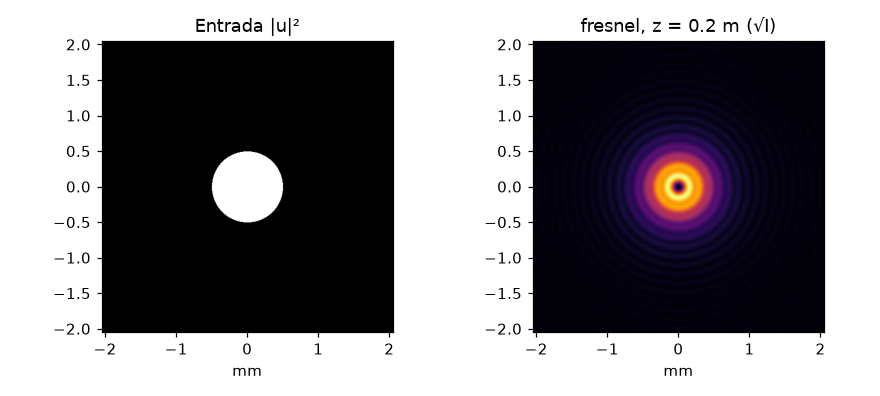

In [31]:
from IPython.display import Image
Image(filename=str(CARPETA / "prop_circular_fresnel_z0.2.png"))